# E2 - Regressão dos dados CTI
**DevLeaders | FECAP | Análise Inferencial de Dados**

Gustavo Pires, Lúcio Vecchio, Luiz Henrique Zaim da Cruz e Eric Aloise.
Professor: Rodnil da Silva Moreira Lisboa.

**Pergunta:** como receita, custos e ano se associam ao resultado líquido das projeções simuladas?
Objetivo associativo contemporâneo, sem interpretação causal ou previsão de anos futuros.

Execução: instalar requirements-e2-dev.txt e iniciar este notebook a partir do clone. No Colab, clonar o repositório e instalar as dependências antes de executar. Não transferir a base privada sem autorização específica. Sem CTI_BASE_LOCAL, usa apenas dados fictícios gerados do zero. A execução salva abaixo utilizou CTI local autorizada; o código sempre informa o modo corrente.

In [1]:
from pathlib import Path
import os, sys, json, platform, importlib.metadata
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"src/cti/regressao.py").exists()), None)
if raiz is None:
    raise RuntimeError("Abra o notebook dentro do clone Projeto6 com a implementação E2.")
if str(raiz) not in sys.path:
    sys.path.insert(0,str(raiz))
from src.cti.dados import carregar, sintetica
from src.cti.regressao import executar, figuras
caminho = os.environ.get("CTI_BASE_LOCAL")
base = carregar(caminho) if caminho else sintetica()
modo = "CTI local" if caminho else "FICTÍCIO"
print("Modo:",modo,"| linhas:",len(base),"| cenários:",base.cenario.nunique())
print("Python",platform.python_version())
print({p:importlib.metadata.version(p) for p in ["pandas","numpy","scikit-learn","statsmodels"]})

Modo: CTI local | linhas: 14400 | cenários: 1200
Python 3.13.14
{'pandas': '3.1.1', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0'}


## Desenho e prevenção de vazamento
Anos 1-11 na análise principal. Regressão simples (receita) e múltipla (receita, custos assinados e indicadores de ano, referência Ano 1).
Unidade monetária em milhões de R$, como convenção acadêmica. Não usamos todas as parcelas da identidade de resultado.
Todos os anos de uma trajetória ficam juntos. Cenários idênticos compartilham grupo. Divisão aproximada de 60/20/20 por grupos, semente 20261105. A escolha usa apenas RMSE de validação; teste não participa da escolha. OLS é ajustado no treino, com covariância agrupada por trajetória.

In [2]:
resultado = executar(base)
print("Partições:", json.dumps(resultado["particoes"],indent=2))
print("Interseção de grupos:", resultado["intersecao_grupos"])
print("Validação:", json.dumps(resultado["validacao"],indent=2))
print("Modelo selecionado:",resultado["modelo"])
print("Teste:", resultado["teste"])
print("Referência (média por ano aprendida só no treino):",resultado["baseline_teste"])

Partições: {
  "treino": {
    "linhas": 7293,
    "grupos": 663,
    "sha_grupos": "01de1da5c0b785ea4c383aedd742767f0c8606da3ea046a749f2395ccb668649"
  },
  "validacao": {
    "linhas": 3465,
    "grupos": 222,
    "sha_grupos": "89de5d3cc0ab9d1ca4c0d52bbbc99c3966861a0f33ad7b2749134a9026cfe8be"
  },
  "teste": {
    "linhas": 2442,
    "grupos": 222,
    "sha_grupos": "0daa5a262c6ce1f3769920776de896d07b52bbf5b9c8da017e6b91cbe1cc1b66"
  }
}
Interseção de grupos: 0
Validação: {
  "simples": {
    "MAE_milhoes": 78.26722618689082,
    "RMSE_milhoes": 100.01176868664845,
    "R2": 0.9851141850176066
  },
  "multipla": {
    "MAE_milhoes": 47.207204665932615,
    "RMSE_milhoes": 69.71475698770898,
    "R2": 0.9927669771519643
  }
}
Modelo selecionado: multipla
Teste: {'MAE_milhoes': 20.06272878704097, 'RMSE_milhoes': 33.62245475732884, 'R2': 0.9983680499983312}
Referência (média por ano aprendida só no treino): {'MAE_milhoes': 36.17143706690287, 'RMSE_milhoes': 83.59309843569409, 'R2': 0.9

## Coeficientes e diagnósticos
Coeficientes monetários: variação em milhões no resultado por milhão de receita/custo, mantendo outras variáveis.
Custos têm sinal negativo; aumento de despesa em módulo é redução do regressor. Indicadores de ano comparam com Ano 1.
Os intervalos agrupados tratam dependência dentro de trajetória, mas não garantem independência entre cenários provenientes do mesmo simulador. BP é diagnóstico exploratório, com calibração limitada em painel.

In [3]:
import pandas as pd
display(pd.DataFrame(resultado["coeficientes"]))
print(json.dumps(resultado["diagnostico"],indent=2,ensure_ascii=False))
print(json.dumps(resultado["identidade_contabil"],indent=2,ensure_ascii=False))

,termo,coeficiente,erro_padrao_cluster,IC95_inferior,IC95_superior
0,const,-1424.923505,118.995096,-1658.149607,-1191.697402
1,receita_milhoes,0.592941,0.024615,0.544698,0.641185
2,custos_milhoes,0.083061,0.077790,-0.069406,0.235527
3,ano_2,-99.581136,12.920876,-124.905588,-74.256685
4,ano_3,-61.430962,8.258324,-77.616979,-45.244944
5,ano_4,-23.589142,8.362439,-39.979222,-7.199063
6,ano_5,100.701092,22.496108,56.609530,144.792654
7,ano_6,174.765860,30.486895,115.012643,234.519077
8,ano_7,123.379678,32.090387,60.483675,186.275680
9,ano_8,92.969601,40.115396,14.344869,171.594334


{
  "breusch_pagan_LM": 295.3821344188918,
  "breusch_pagan_p_exploratorio": 4.375490055078223e-56,
  "correlacao_residuo_defasado": 0.9505937027477538,
  "VIF": {
    "receita_milhoes": 61.72896436406511,
    "custos_milhoes": 24.776324515544612,
    "ano_2": 2.8020489673609412,
    "ano_3": 4.330556311710315,
    "ano_4": 4.742776367576532,
    "ano_5": 13.799794353083747,
    "ano_6": 16.565148180792427,
    "ano_7": 11.098596718695843,
    "ano_8": 12.663754860261976,
    "ano_9": 15.68344349914355,
    "ano_10": 35.24005347580207,
    "ano_11": 81.86392833265637
  },
  "nota": "BP é exploratório: dependência em painel afeta sua calibração. IC agrupado por trajetória; nenhuma conclusão causal."
}
{
  "parcelas": [
    "DRE - Receita",
    "DRE - Tributos",
    "DRE - Custos",
    "DRE - Depreciação e Amortização",
    "DRE - Resultado Financeiro",
    "DRE - Outros Resultados Operacionais",
    "DRE - Imposto de Renda e Contribuição Social"
  ],
  "residuo_max_reais": 5.05447387695

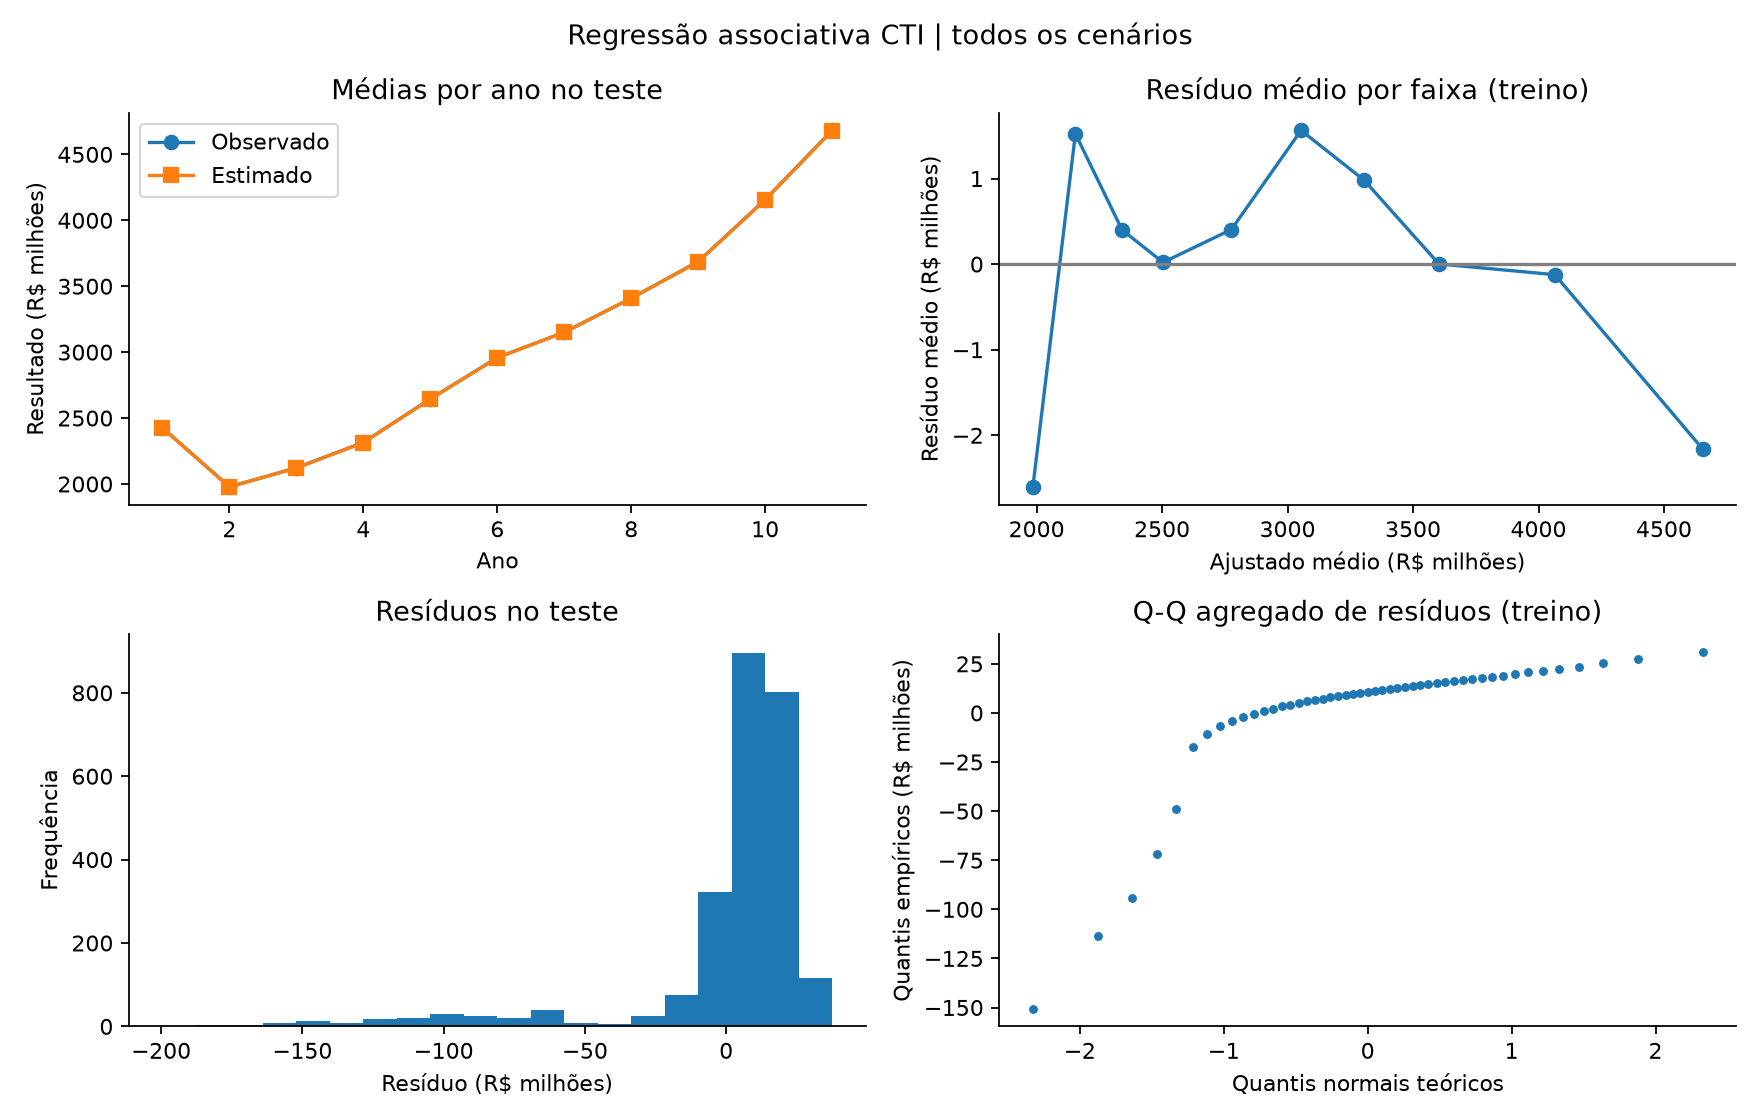

In [4]:
from IPython.display import display, Image
destino = raiz/"src/data/processed/e2/notebook"
figura = figuras(resultado,destino)
display(Image(filename=str(figura)))

## Sensibilidade: cópias repetidas e encerramento
Executamos o mesmo procedimento com trajetórias únicas e incluindo Ano 12. A análise com Ano 12 é de outro regime e não pode ser usada para escolher retrospectivamente a análise principal pelo maior R².

In [5]:
sem_copias = executar(base,unicas=True)
com_encerramento = executar(base,incluir_encerramento=True)
display(pd.DataFrame([
    {"Recorte":"Principal (1–11)",**resultado["teste"]},
    {"Recorte":"Sem cópias (1–11)",**sem_copias["teste"]},
    {"Recorte":"Inclui encerramento (1–12)",**com_encerramento["teste"]}
]))
print("Partições sem cópias:",sem_copias["particoes"])

,Recorte,MAE_milhoes,RMSE_milhoes,R2
0,Principal (1–11),20.062729,33.622455,0.998368
1,Sem cópias (1–11),20.062729,33.622455,0.998368
2,Inclui encerramento (1–12),21.592331,36.277711,0.999266


Partições sem cópias: {'treino': {'linhas': 7293, 'grupos': 663, 'sha_grupos': '01de1da5c0b785ea4c383aedd742767f0c8606da3ea046a749f2395ccb668649'}, 'validacao': {'linhas': 2442, 'grupos': 222, 'sha_grupos': '89de5d3cc0ab9d1ca4c0d52bbbc99c3966861a0f33ad7b2749134a9026cfe8be'}, 'teste': {'linhas': 2442, 'grupos': 222, 'sha_grupos': '0daa5a262c6ce1f3769920776de896d07b52bbf5b9c8da017e6b91cbe1cc1b66'}}


## Interpretação e limites
A soma de sete parcelas do DRE reproduz o resultado com diferença de arredondamento numérico. O modelo usa apenas receita, custos e ano. O produto das taxas agregadas de tributos e IR (aproximadamente 0,6008 na base CTI) é uma comparação descritiva, não prova de que o coeficiente parcial 0,5929 seja repasse tributário. Omissão de parcelas é hipótese a investigar, não explicação causal demonstrada.

Na execução CTI de referência, o modelo múltiplo reduz o RMSE de teste em relação à média por ano. O R² alto também reflete tendências temporais comuns e a ligação contábil entre receita, custos e resultado.
A colinearidade elevada torna coeficientes individuais instáveis; o intervalo do custo inclui zero. Isso não significa que custos não importem: o modelo é condicionado a receita e ano.
A correlação residual defasada é alta e há heterocedasticidade. Não usar erros-padrão iid, interpretar p-valores como causalidade ou transformar a equação em recomendação econômica.
O grupo de trajetórias repetidas caiu na validação nesta semente. A remoção de cópias não alterou treino/teste nem o modelo escolhido, explicando métricas finais idênticas. Essa igualdade não vale universalmente para outras divisões.
Ano 12 exige cautela de encerramento. Nenhum dado individual ou ID de cenário é salvo nas saídas; figuras apresentam distribuições e agregações.

**Fontes:** base CTI v3 e pipeline E1; documentação de GroupShuffleSplit/scikit-learn e OLS com covariância agrupada/statsmodels. O relatório PDF documenta números e limitações da mesma execução.

In [6]:
# Evidência agregada da execução. Não exporta linhas individuais.
resumo = {"modo":modo,"principal":resultado["teste"],"sem_copias":sem_copias["teste"],
          "encerramento":com_encerramento["teste"],"intersecao_grupos":resultado["intersecao_grupos"]}
assert resultado["intersecao_grupos"] == 0
print("EXECUÇÃO CONCLUÍDA",json.dumps(resumo,ensure_ascii=False))

EXECUÇÃO CONCLUÍDA {"modo": "CTI local", "principal": {"MAE_milhoes": 20.06272878704097, "RMSE_milhoes": 33.62245475732884, "R2": 0.9983680499983312}, "sem_copias": {"MAE_milhoes": 20.06272878704097, "RMSE_milhoes": 33.62245475732884, "R2": 0.9983680499983312}, "encerramento": {"MAE_milhoes": 21.592330809079478, "RMSE_milhoes": 36.27771073522824, "R2": 0.9992655103254854}, "intersecao_grupos": 0}
